In [ ]:
import kagglehub
path = kagglehub.dataset_download("fedesoriano/heart-failure-prediction")

Using Colab cache for faster access to the 'heart-failure-prediction' dataset.


In [ ]:
import pandas as pd
import os
file_name = os.listdir(path)[0]
full_path = os.path.join(path, file_name)
df = pd.read_csv(full_path)
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [ ]:
df.info()
df.describe()
df['HeartDisease'].value_counts()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


,count
HeartDisease,
1,508
0,410


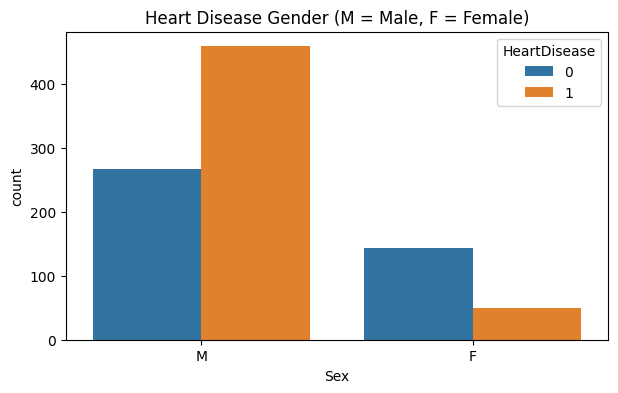

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Sex', hue='HeartDisease')
plt.title('Heart Disease Gender (M = Male, F = Female)')
plt.show()



plt.show()

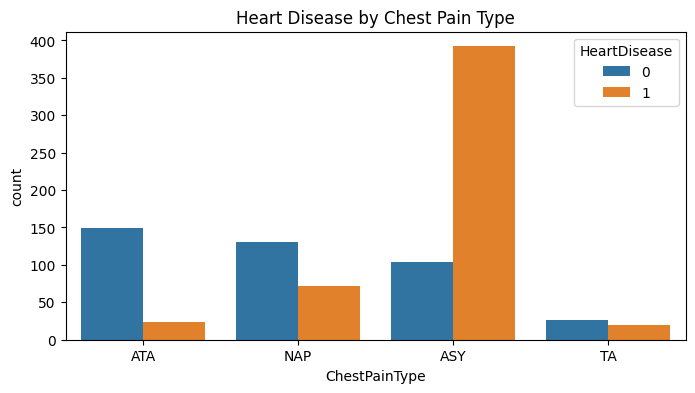

In [ ]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='ChestPainType', hue='HeartDisease')
plt.title('Heart Disease by Chest Pain Type')
plt.show()

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
df_encoded = pd.get_dummies(df, drop_first=True)
X = df_encoded.drop('HeartDisease', axis=1)
y = df_encoded['HeartDisease']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train.shape, X_test.shape")

X_train.shape, X_test.shape


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)
print("AI model ki training puri hui!")

AI model ki training puri hui!


In [ ]:
pridictions = rf_model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, pridictions)
print(f"model ki Accuracy: {accuracy*100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(y_test, pridictions))

model ki Accuracy: 87.50%

Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.86      0.85        77
           1       0.90      0.89      0.89       107

    accuracy                           0.88       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.88      0.88      0.88       184



In [ ]:
import numpy as np
#(Age=55, Male, ChestPain=ASY, Restiing=140, Cholestrol=289, FastingBS=1, etc.)
sample_patient = X_test_scaled[0].reshape(1, -1)
prediction = rf_model.predict(sample_patient)
probability = rf_model.predict_proba(sample_patient)
if prediction[0] == 1:
    print(f"AI prediction: patient does have heart disease! {probability[0][1]*100:.1f}%")
else:
    print(f"AI prediction:Patient does not have heart disease! {probability[0][0]*100:.1f}%")


AI prediction:Patient does not have heart disease! 90.0%
